In [1]:
import importlib
import numpy as np
import torch
import os
import sys
import time
sys.path.append(os.path.relpath("../src"))
import dataloader as dl
from torch.utils.data import Dataset, DataLoader, random_split
torch.cuda.is_available()

False

In [23]:
import json

importlib.reload(dl)
for i in [3.5]:
    path_train = f"/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_02_24_AutoencoderLSTM_9_813_channel{i}/"
    with open(path_train + "InfoDict.json", "r") as out_file:
        InfoDict = json.load(out_file)

    partial_num = 1 if i==17 else 0
    # Load dataset used for training
    dataset_dict = InfoDict["dataset_dict"]
    for data_label in [0,8]:
        channel_out = dataset_dict["channel_out"]
        channel = int(dataset_dict["file_paths"][channel_out][-11:-8])
        dir_path_inj = f"/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected/channel{channel}/"
        if partial_num!=0:
            dataset_dict["file_paths"] = [f"/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_{ch:03}_{partial_num:03}.bin" for ch in [3,5,9,11,13,15,17,19]]

        dataset_dict["file_paths"][channel_out] = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}.bin".format(data_label,channel,partial_num)
        positions_path = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}.pos_selected.pt".format(data_label, channel,partial_num)
        dataset_dict["StdCut"] = [0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
        dataset_dict["win_shift"] = 1024*2
        dataset_dict["positions_path"] = positions_path
        datasetSTFT_pulses = dl.DatasetSTFTFromBinary(**dataset_dict, dtype=np.uint32)
        print(len(datasetSTFT_pulses))
        #datasetSTFT_pulses.select_event(256,HasPulse=True,update_value=True)

14541
14539
14580
14582
14535
14583
13572
14062


In [9]:
import json
importlib.reload(dl)
stdc = [0.0007,0.0008]
for i,channel in enumerate([3,5]):
    path_train = f"/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_02_24_AutoencoderLSTM_9_813_channel{channel}/"
    dataset = dl.DatasetFromBinary([f"/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_{channel:03}_000.bin"],win_length=2000,StdCut=[stdc[i]])
    print(len(dataset))
    dataset.select_event(256)
    print(len(dataset))

134217


/feynman/work/projets/cupid/scratch/mpageot/python_project/ML_denoising/DenoisingAux/WitnessDenoisingAE/test/../src/dataloader.py:224: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.StdCut = StdCut if StdCut is None else torch.tensor(StdCut)


133153
134217
133078


In [42]:
importlib.reload(dl)
dir_path = "/feynman/work/projets/cupid/data/LSM/RUN9/"
channel_list = [9,11,13,15,17,19]
file_paths = [dir_path + "000813_20230628T161508_{:03}_000.bin".format(i) for i in channel_list]
n_channel = 2 * len(file_paths)
channel_guess = 7
win_length = 4095
n_fft = 320
start_window = 1024
end_window = 1024 * 3
out_window_size = end_window - start_window
hop_length = 64
positions_path=None
# positions_path = "/feynman/work/projets/cupid/data/LSM/RUN9/positions/pos_start_813_"+"_".join([str(I) for I in channel_list])+".pt"
# positions_path = positions_path if os.path.isfile(positions_path) else None
# dir_path_inj = "/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected/"
# positions_path = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_000.pos.pt".format(0, 9)
globalStd_path = "/feynman/work/projets/cupid/data/LSM/RUN9/positions/globalStd_"+"_".join([str(I) for I in channel_list])+".pt"
globalStd = None if not os.path.isfile(globalStd_path) else torch.load(globalStd_path)
print(globalStd)
print(positions_path)
# dataset_dict = dict(file_paths=file_paths, positions_path=positions_path, win_length=win_length,
#                     start_window=1024, end_window=1024 * 3, channel_out=channel_guess,
#                     n_fft=n_fft, hop_length=hop_length)
# STFT_dataset = dl.DatasetSTFTFromBinary(**dataset_dict, dtype=np.uint32)
# StdCut = [sum(np.fromfile("/feynman/work/projets/cupid/data/LSM/RUN9/anaysis/000813_20230628T161508_{:03}_000.bin_spec.bin.info".format(i))) for i in channel_list]
StdCut = [0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
print(StdCut)
dataset_dict = dict(file_paths=file_paths, positions_path=positions_path, StdCut=StdCut, win_length=win_length,globalStd=globalStd,
                    start_window=1024, end_window=1024 * 3)

dataset = dl.DatasetFromBinary(**dataset_dict, dtype=np.uint32)
# print(len(dataset))
# stds = torch.ones((len(dataset), len(dataset.file_paths)))
# loader = DataLoader(dataset, batch_size=256, shuffle=False)
# for index, batch in loader:
#     std = torch.std(batch, dim=2)
#     stds[index] = std

print(len(dataset))
dataset.select_event(256)
print(len(dataset))
dataset.exclude_positions("/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected/pup_n1-d0_000813_20230628T161508_009_000.pos.pt")
print(len(dataset))
print(dataset.globalStd)
# torch.save(dataset.globalStd,"/feynman/work/projets/cupid/data/LSM/RUN9/positions/globalStd_"+"_".join([str(I) for I in channel_list])+".pt")

tensor([0.0005, 0.0004, 0.0005, 0.0004, 0.0003, 0.0012])
None
[0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
65552
59298
38502
tensor([0.0005, 0.0004, 0.0005, 0.0004, 0.0003, 0.0012])


In [52]:
import matplotlib.pyplot as plt
data_label = 8
channel=9
positions_path = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_000.pos_selected.pt".format(data_label, channel)
pos = torch.load(positions_path).numpy().reshape(1,-1).T
print(positions_path)
print(pos)

/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected/pup_n1-d8_000813_20230628T161508_009_000.pos_selected.pt
[[    12495]
 [    17493]
 [    22497]
 ...
 [109177507]
 [109182494]
 [109187491]]


In [43]:
torch.save(dataset.globalStd,"/feynman/work/projets/cupid/data/LSM/RUN9/positions/globalStd_"+"_".join([str(I) for I in channel_list])+".pt")
torch.save(dataset.positions,"/feynman/work/projets/cupid/data/LSM/RUN9/positions/pos_start_813_"+"_".join([str(I) for I in channel_list])+".pt")

/tmp/ipykernel_1187984/554855207.py:2: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 1.22.0)
  from scipy.optimize import curve_fit


0.00026377169023542854


0.30733842961836183
0.27429690281238905


##### channel 9 #####


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


cutted pileup raw:  0.65 /// cutted single raw:  0.1 	 /// BI :9.26e-05
cutted pileup corrected:  0.66 	 /// cutted single corrected:  0.1 	 /// BI :9.04e-05
cutted pileup raw pupspec:  0.75 	 /// cutted single raw pupspec:  0.1 	 /// BI :6.72e-05


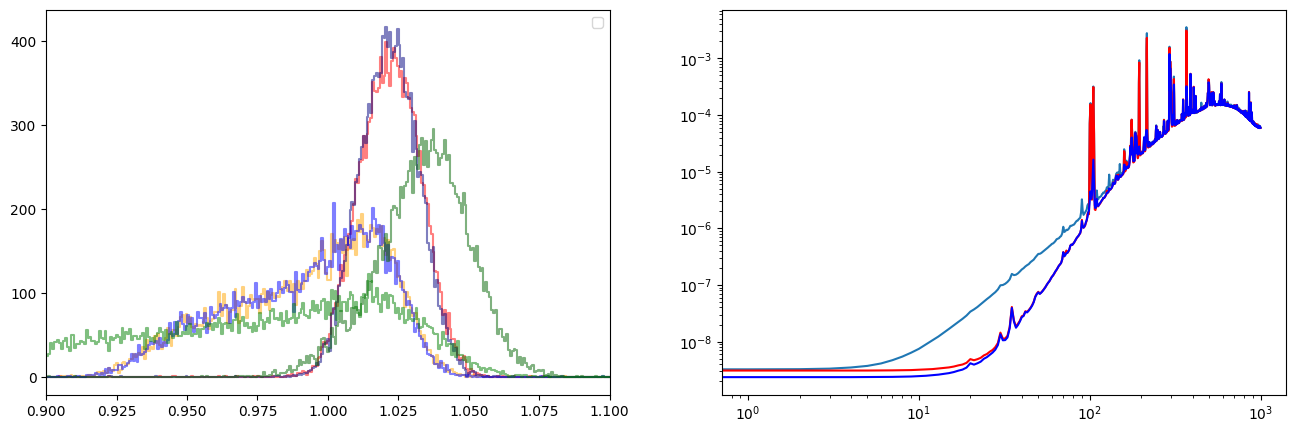

In [ ]:
import matplotlib.pyplot as plt


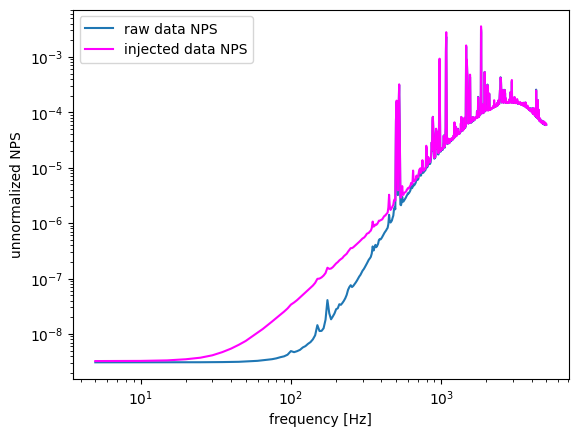

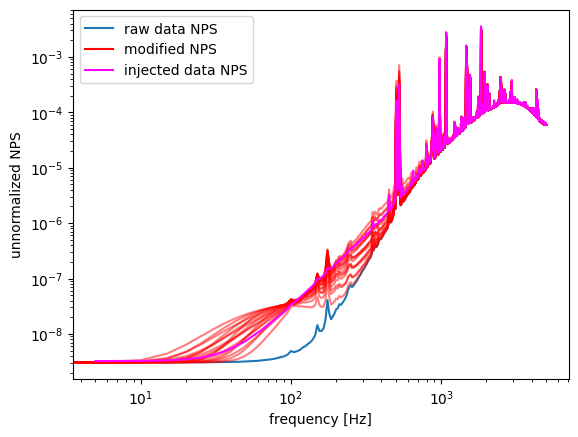

3 1
4.2766658195556086e-05


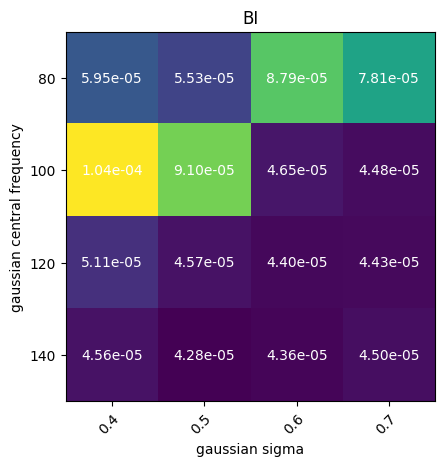

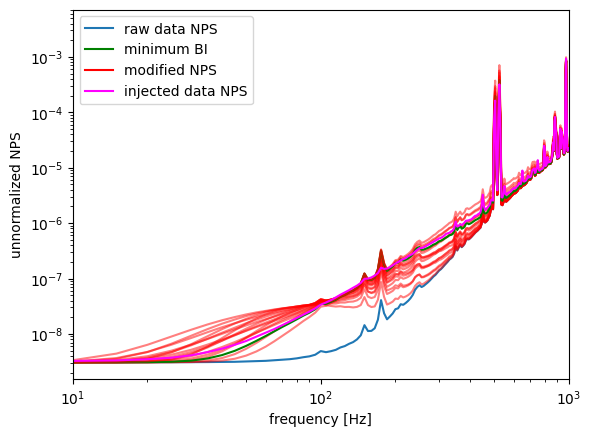

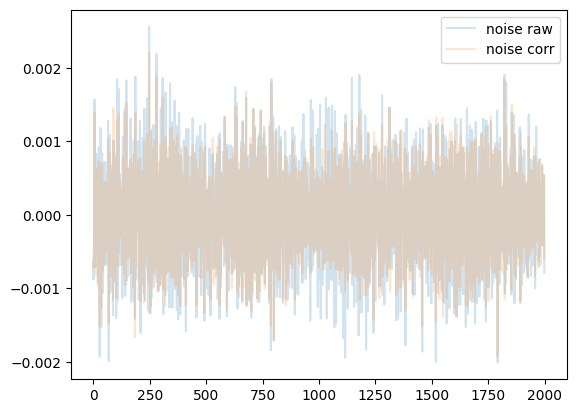

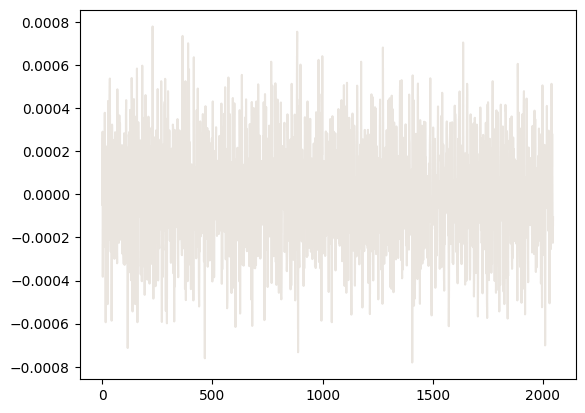

3


True

25_01_20


'/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_01_15_AutoencoderSkipLay'